#### Configuration
Compare cancellation off/on across operators and layer scopes; the 385,000-completion run is preloaded.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from extensions.experiments import Sweep, generate_run, judge_run

RUN = False
config = Sweep(
    notebook='03_drift_lqr_ablation', model_name='Qwen/Qwen3-4B',
    concept='football', prompt='Once upon a time', trials=1000,
    lambdas=tuple(range(1, 9)), r_values=(1., 10.), q=0.1, qf=0.1,
    last_n=(4, 8, None), every=(1,),
    operators=('Identity', 'Mean Jacobian', 'Random', 'Steering DMD'),
    drift_weights=(0., 2.), seed=0, random_seed=0,
    direction_samples=200, jacobian_samples=50, max_ctx=32, direction_batch=8,
    max_new_tokens=96, temperature=0.7, top_p=0.95,
    generation_batch=500, trace_batch=100, judge_batch=256, judge_chunk=2048,
    dtype='auto', device_map='auto',
)
PLOT_R, PLOT_EVERY, TARGETS = 10., 1, (0.75, 0.9)
COLORS, CMAPS = {0.: 'tab:blue', 2.: 'tab:orange'}, {0.: 'Blues', 2.: 'Oranges'}
RUN_DIR = config.run_dir

#### Generate
RUN loads or fits the selected model’s operators, then resumes generation with matched lambda seeds.

In [2]:
if RUN:
    generate_run(config)

#### Judge and load
Resumed judging needs no generation; ordinary review loads saved summaries and no models.

In [3]:
if RUN:
    judge_run(config)
summary = pd.read_csv(RUN_DIR / 'summary.csv')
metadata = json.loads((RUN_DIR / 'config.json').read_text())
num_layers = metadata['layers']
scopes = sorted({num_layers if n is None else n for n in config.last_n}, reverse=True)
selected = summary.loc[summary.R.eq(PLOT_R) & summary.every.eq(PLOT_EVERY)
                       & summary.N.isin(scopes) & summary.operator.isin(config.operators)
                       & summary.drift_weight.isin(config.drift_weights)
                       & summary['lambda'].isin(config.lambdas)]
baseline = summary.loc[summary.operator.eq('Unsteered')]

#### Matched concept rates
Interpolate the first crossing along increasing lambda; do not extrapolate.

In [4]:
def first_crossing(curve, target):
    curve = curve.sort_values('lambda').reset_index(drop=True)
    columns = ['lambda', 'coherent', 'median_push_energy', 'orthogonal', 'along_v']
    missing = dict.fromkeys(columns, np.nan)
    reached = np.flatnonzero(curve.concept.to_numpy() >= target)
    if len(curve) != len(config.lambdas) or not len(reached):
        return missing
    index = reached[0]
    high = curve.iloc[index]
    if high.concept == target:
        return high[columns].to_dict()
    if index == 0:
        return missing
    low = curve.iloc[index - 1]
    fraction = (target - low.concept) / (high.concept - low.concept)
    return (low[columns] + fraction * (high[columns] - low[columns])).to_dict()

keys = ['N', 'R', 'every', 'operator', 'drift_weight']
rows = [dict(zip(keys, values)) | {'target_concept': target} | first_crossing(curve, target)
        for values, curve in summary.loc[summary.N.gt(0)].groupby(keys) for target in TARGETS]
matched = pd.DataFrame(rows)
matched.to_csv(RUN_DIR / 'matched.csv', index=False)

#### Summary
Coherence and median normalized push energy at the selected penalty and interval.

In [5]:
shown = matched.loc[matched.R.eq(PLOT_R) & matched.every.eq(PLOT_EVERY) & matched.N.isin(scopes)
                    & matched.operator.isin(config.operators)]
table = shown.pivot(index=['N', 'operator', 'target_concept'], columns='drift_weight',
                    values=['coherent', 'median_push_energy'])
display(table.reindex(scopes, level='N').round(3))

coherent        median_push_energy       
drift_weight                         0.0    2.0                0.0    2.0
N  operator      target_concept                                          
36 Identity      0.75              0.889  0.955              0.021  0.049
                 0.90              0.800  0.923              0.030  0.079
   Mean Jacobian 0.75              0.796  0.962              0.015  0.030
                 0.90              0.462  0.924              0.022  0.043
   Random        0.75              0.878  0.955              0.036  0.136
                 0.90              0.821  0.919              0.046  0.201
   Steering DMD  0.75              0.926  0.958              0.057  1.117
                 0.90              0.802  0.926              0.082  1.346
8  Identity      0.75                NaN    NaN                NaN    NaN
                 0.90                NaN    NaN                NaN    NaN
   Mean Jacobian 0.75              0.833  0.943              0.035  0.042
                 0.90                NaN  0.910                NaN  0.051
   Random        0.75                NaN    NaN                NaN    NaN
                 0.90                NaN    NaN                NaN    NaN
   Steering DMD  0.75              0.936  0.953              0.057  0.056
                 0.90              0.910    NaN              0.075    NaN
4  Identity      0.75                NaN    NaN                NaN    NaN
                 0.90                NaN    NaN                NaN    NaN
   Mean Jacobian 0.75                NaN    NaN                NaN    NaN
                 0.90                NaN    NaN                NaN    NaN
   Random        0.75                NaN    NaN                NaN    NaN
                 0.90                NaN    NaN                NaN    NaN
   Steering DMD  0.75                NaN    NaN                NaN    NaN
                 0.90                NaN    NaN                NaN    NaN

#### Coherence versus concept
Rows separate layer scopes; each panel compares no cancellation with measured cancellation.

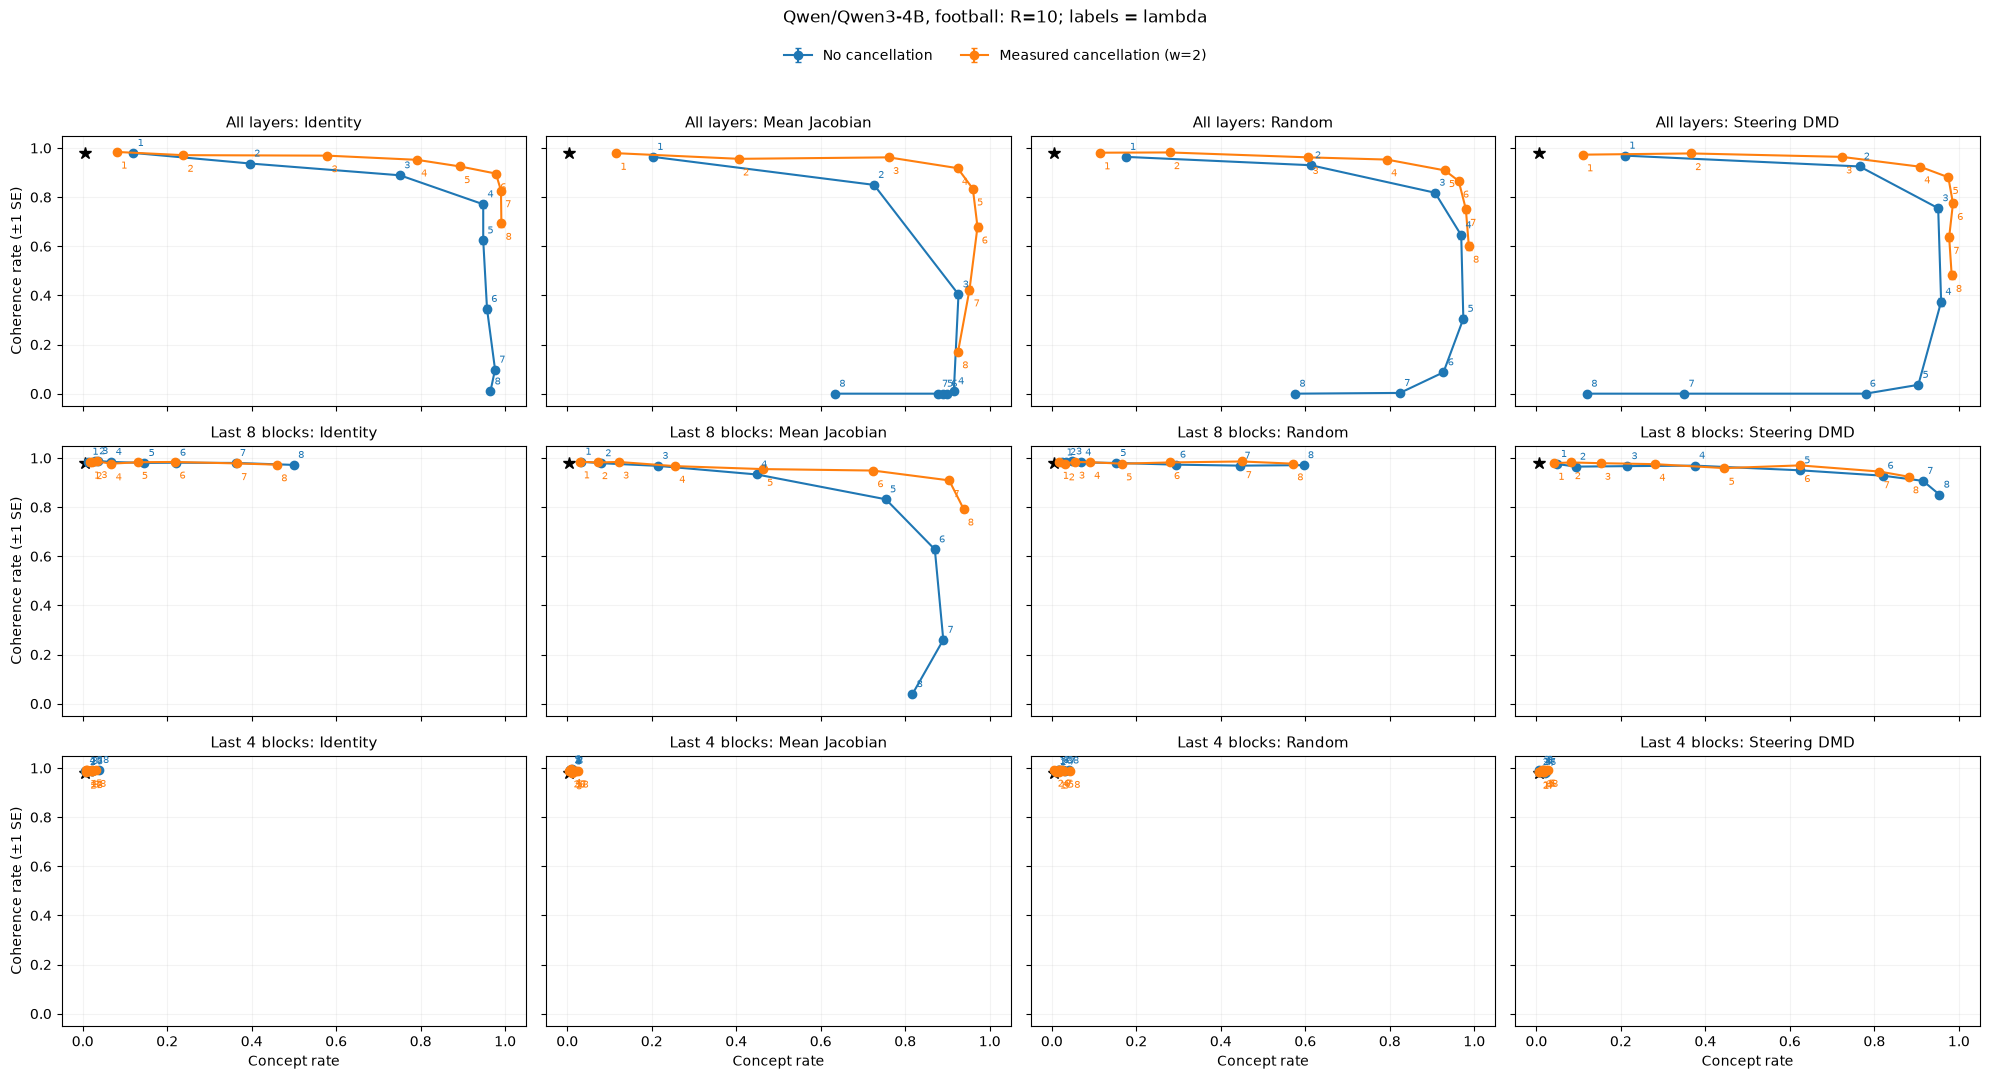

In [6]:
fig, axes = plt.subplots(len(scopes), len(config.operators), figsize=(5 * len(config.operators), 3.6 * len(scopes)),
                         sharex=True, sharey=True, squeeze=False)
for row, N in zip(axes, scopes):
    scope = 'All layers' if N == num_layers else f'Last {N} blocks'
    for ax, name in zip(row, config.operators):
        panel = selected.loc[selected.N.eq(N) & selected.operator.eq(name)]
        for weight, curve in panel.groupby('drift_weight'):
            curve = curve.sort_values('lambda')
            label = 'No cancellation' if weight == 0 else f'Measured cancellation (w={weight:g})'
            ax.errorbar(curve.concept, curve.coherent, yerr=curve.coherent_se, marker='o', capsize=2,
                        color=COLORS[weight], label=label)
            for concept, coherent, strength in curve[['concept', 'coherent', 'lambda']].itertuples(index=False, name=None):
                ax.annotate(f'{strength:g}', (concept, coherent), fontsize=7, color=COLORS[weight],
                            xytext=(3, 5 if weight == 0 else -12), textcoords='offset points')
        ax.plot(baseline.concept, baseline.coherent, 'k*', ms=9)
        ax.set_title(f'{scope}: {name}', fontsize=11)
        ax.grid(alpha=0.15)
for ax in axes[-1]:
    ax.set_xlabel('Concept rate')
for ax in axes[:, 0]:
    ax.set_ylabel('Coherence rate (±1 SE)')
axes[0, 0].set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.97), ncol=2, frameon=False)
fig.suptitle(f'{config.model_name}, {config.concept}: R={PLOT_R:g}; labels = lambda', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(RUN_DIR / f'concept_coherence_r{PLOT_R:g}.png', dpi=150)
plt.show()

#### Off-concept change versus concept shift
Darker dots mean higher coherence; larger dots mean higher concept rate.

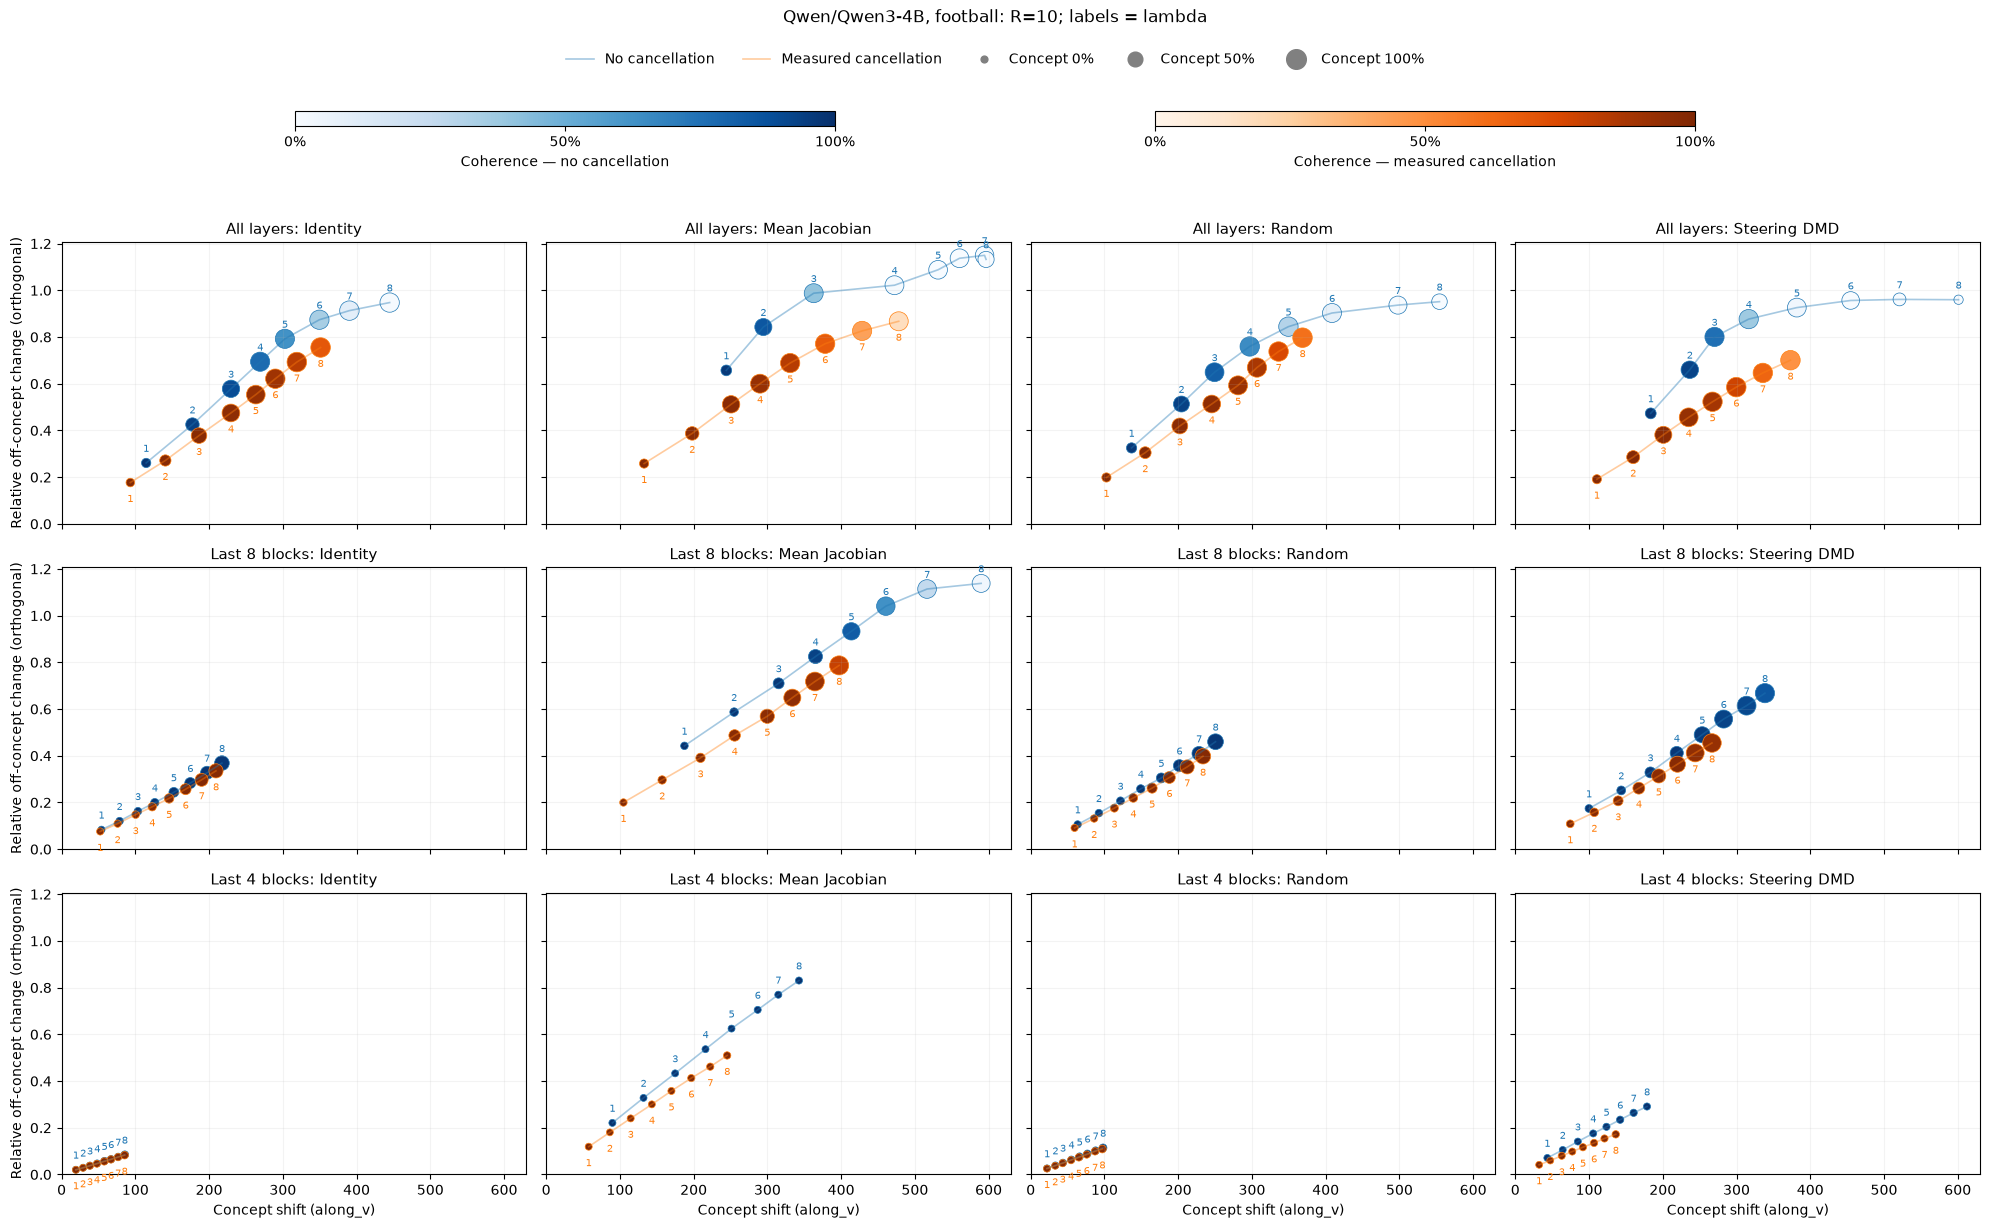

In [7]:
fig, axes = plt.subplots(len(scopes), len(config.operators), figsize=(5 * len(config.operators), 4.1 * len(scopes)),
                         sharex=True, sharey=True, squeeze=False)
for row, N in zip(axes, scopes):
    scope = 'All layers' if N == num_layers else f'Last {N} blocks'
    for ax, name in zip(row, config.operators):
        panel = selected.loc[selected.N.eq(N) & selected.operator.eq(name)]
        for weight, curve in panel.groupby('drift_weight'):
            curve = curve.sort_values('lambda')
            label = 'No cancellation' if weight == 0 else 'Measured cancellation'
            ax.plot(curve.along_v, curve.orthogonal, color=COLORS[weight], linewidth=1.2, alpha=0.4, label=label)
            ax.scatter(curve.along_v, curve.orthogonal, s=24 + 176 * curve.concept, c=curve.coherent,
                       cmap=CMAPS[weight], vmin=0, vmax=1, edgecolors=COLORS[weight], linewidths=0.5)
            for along, orthogonal, strength in curve[['along_v', 'orthogonal', 'lambda']].itertuples(index=False, name=None):
                ax.annotate(f'{strength:g}', (along, orthogonal), color=COLORS[weight], fontsize=7,
                            xytext=(0, 8 if weight == 0 else -14), ha='center', textcoords='offset points')
        ax.set_title(f'{scope}: {name}', fontsize=11)
        ax.grid(alpha=0.15)
for ax in axes[-1]:
    ax.set_xlabel('Concept shift (along_v)')
for ax in axes[:, 0]:
    ax.set_ylabel('Relative off-concept change (orthogonal)')
axes[0, 0].set(xlim=(0, None), ylim=(0, None))
handles, labels = axes[0, 0].get_legend_handles_labels()
handles += [plt.Line2D([], [], linestyle='none', marker='o', color='0.5',
                       markersize=np.sqrt(24 + 176 * rate), label=f'Concept {rate:.0%}') for rate in (0, 0.5, 1)]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.97), ncol=5, frameon=False)
fig.suptitle(f'{config.model_name}, {config.concept}: R={PLOT_R:g}; labels = lambda', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.86))
for i, (weight, cmap) in enumerate(CMAPS.items()):
    bar = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap=cmap),
                       cax=fig.add_axes((0.15 + 0.43 * i, 0.90, 0.27, 0.012)), orientation='horizontal')
    bar.set_label(f'Coherence — {"no cancellation" if weight == 0 else "measured cancellation"}')
    bar.set_ticks([0, 0.5, 1], labels=['0%', '50%', '100%'])
fig.savefig(RUN_DIR / f'orthogonal_vs_along_v_r{PLOT_R:g}.png', dpi=150)
plt.show()

In [8]:
compared = shown.loc[shown.N.eq(num_layers) & shown.target_concept.eq(0.9)
                     & shown.drift_weight.eq(2)].dropna(subset=['coherent', 'median_push_energy'])
if len(compared):
    cheapest = compared.loc[compared.median_push_energy.idxmin()]
    result = (f'At 90% concept, all-layer measured cancellation has {compared.coherent.min():.1%}–'
              f'{compared.coherent.max():.1%} coherence among the operators that bracket this target. '
              f'{cheapest.operator} uses the least median normalized push energy ({cheapest.median_push_energy:.4f}).')
else:
    result = 'The selected all-layer cancellation curves do not bracket 90% concept; no matched-target claim is available.'
display(Markdown('#### Result\n' + result))

#### Result
At 90% concept, all-layer measured cancellation has 91.9%–92.6% coherence among the operators that bracket this target. Mean Jacobian uses the least median normalized push energy (0.0434).